In [1]:
import matplotlib.pyplot as plt
import numpy as np
from pyspark.sql.functions import expr
import rasterio
from sedona.spark import SedonaContext

In [2]:
# https://sedona.apache.org/latest/setup/install-python/#prepare-sedona-spark-jar
config = (
    SedonaContext.builder()
    .master("spark://sacramento.cs.colostate.edu:30156")
    .config(
        "spark.jars.packages",
        "org.apache.sedona:sedona-spark-4.1_2.13:1.9.1,"
        "org.datasyslab:geotools-wrapper:1.9.1-33.5",
    )
    .config(
        "spark.jars.repositories",
        "https://artifacts.unidata.ucar.edu/repository/unidata-all",
    )
    .getOrCreate()
)
sd = SedonaContext.create(config)

https://artifacts.unidata.ucar.edu/repository/unidata-all added as a remote repository with the name: repo-1
:: loading settings :: url = jar:file:/usr/local/spark/4.1.1-bin-hadoop3/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /s/chopin/a/grad/C837273242/.ivy2.5.2/cache
The jars for the packages stored in: /s/chopin/a/grad/C837273242/.ivy2.5.2/jars
org.apache.sedona#sedona-spark-4.1_2.13 added as a dependency
org.datasyslab#geotools-wrapper added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-7e647bc7-0edc-47bc-b0eb-cde26506d51c;1.0
	confs: [default]
	found org.apache.sedona#sedona-spark-4.1_2.13;1.9.1 in central
	found org.apache.sedona#sedona-common;1.9.1 in central
	found org.apache.commons#commons-math3;3.6.1 in local-m2-cache
	found org.locationtech.jts#jts-core;1.20.0 in local-m2-cache
	found org.wololo#jts2geojson;0.16.1 in central
	found org.locationtech.spatial4j#spatial4j;0.8 in central
	found or

In [21]:
FOCO_FULL_FILE = "/final/data/full_embed_tiles/"
FOCO_QUANT_FILE = "/final/data/quant_embed_tiles/"
TARGET_FILE = "/final/data/SurfaceFuels_COWRA22_cog.tif"

In [30]:
metadata = (
    sd.read.format("geotiff.metadata")
    .option("recursiveFileLookup", True)
    .load("/final/data/")
)
metadata.show(100, truncate=False)

+----------------------------------------------------------------------------------------------------+------+-----------+-----+------+--------+-----+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [15]:
foco_full_df = (
    sd.read.format("raster")
    .option("tileWidth", "256")
    .option("tileHeight", "256")
    .option("recursiveFileLookup", True)
    .load(FOCO_FULL_FILE)
)
foco_full_df.show(truncate=False)

+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+---+---+-------------------------------+
|rast                                                                                                                                                                          |x  |y  |name                           |
+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+---+---+-------------------------------+
|GridCoverage2D["genericCoverage", GeneralBounds[(488350.0, 4494500.0), (490910.0, 4497060.0)], DefaultProjectedCRS["WGS 84 / UTM zone 13N"]]\n└ Image=RenderedImageAdapter[]\n|0  |0  |2022_foco_bbox_full_cog_4_4.tif|
|GridCoverage2D["genericCoverage", GeneralBounds[(490910.0, 4494500.0), (493470.0, 4497060.0)], DefaultProjectedCRS["WGS 84 / UTM zo

In [ ]:
# One partition per input file. Just what we want.
foco_full_df.rdd.getNumPartitions()

30

In [ ]:
foco_full_df.count()  # Num tiles. Much faster with partitions.

432

In [22]:
foco_quant_cog_df = (
    sd.read.format("raster")
    .option("tileWidth", "256")
    .option("tileHeight", "256")
    .option("recursiveFileLookup", True)
    .load(FOCO_QUANT_FILE)
)
foco_quant_cog_df.show(truncate=False)

+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+---+---+----------------------------+
|rast                                                                                                                                                                          |x  |y  |name                        |
+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+---+---+----------------------------+
|GridCoverage2D["genericCoverage", GeneralBounds[(457630.0, 4494500.0), (460190.0, 4497060.0)], DefaultProjectedCRS["WGS 84 / UTM zone 13N"]]\n└ Image=RenderedImageAdapter[]\n|0  |0  |2022_foco_bbox_quant_4_1.tif|
|GridCoverage2D["genericCoverage", GeneralBounds[(460190.0, 4494500.0), (462750.0, 4497060.0)], DefaultProjectedCRS["WGS 84 / UTM zone 13N"]]\n└

In [23]:
foco_quant_cog_df.rdd.getNumPartitions()

27

In [24]:
print(foco_quant_cog_df.count())  # ~432 if tiling worked ((width // 256) * (height // 256))
foco_quant_cog_df.printSchema()   # rast plus tile x/y columns
print(sd.sparkContext.defaultParallelism)

432
root
 |-- rast: raster (nullable = true)
 |-- x: integer (nullable = true)
 |-- y: integer (nullable = true)
 |-- name: string (nullable = true)

18


In [25]:
target_df = (
    sd.read.format("raster")
    .option("tileWidth", "256")
    .option("tileHeight", "256")
    .load(TARGET_FILE)
)
target_df.show(truncate=False)

+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+---+---+----------------------------+
|rast                                                                                                                                                                                                                                                                                                                             |x  |y  |name                        |
+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [ ]:
feature_df = foco_quant_cog_df.withColumn("f_extent", expr("RS_Envelope(rast)"))  # EPSG:32613
target_df = target_df.withColumn("t_extent", expr("RS_Envelope(rast)"))           # EPSG:26913

# Join where the feature tile bbox intersects the target tile bbox, and
# reproject and resample target raster to match feature tile's
# CRS, extent, and 10m resolution.
# NearestNeighbor resampling preserves categorical data.
aligned_df = (
    feature_df.alias("f")
        .join(
            target_df.alias("t"),
            expr("ST_Intersects(f.f_extent, ST_Transform(t.t_extent, 'EPSG:26913', 'EPSG:32613'))")
        ).select(
            expr("f.rast").alias("feature_raster"),
            expr("RS_ReprojectMatch(t.rast, f.rast, 'NearestNeighbor')").alias("target_raster_aligned")
        )
).cache()

In [63]:
aligned_df.show()

26/11/12 17:04:10 WARN JoinQuery: UseIndex is true, but no index exists. Will build index on the fly.


+--------------------+---------------------+
|      feature_raster|target_raster_aligned|
+--------------------+---------------------+
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCoverage2D["g...| GridCoverage2D["g...|
|GridCover

In [ ]:
# Example numpy use: we can get a 256x256 tile as an array.
aligned_target_arr = aligned_df.select("target_raster_aligned").collect()
tile = aligned_target_arr[0].target_raster_aligned.as_numpy()
tile.shape

26/11/12 16:44:51 WARN JoinQuery: UseIndex is true, but no index exists. Will build index on the fly.


(1, 256, 256)

### Can we save the cropped, aligned, and resampled target data?

In [ ]:
# https://sedona.apache.org/latest/tutorial/raster/#writing-rasters-reference
# This produces many small tiles.

ALIGNED_TARGET_OUTPUT_DIR = "/final/data/surface_fuels_aligned_tiles"

# tileSize=1024
(
    aligned_df.select(expr("RS_AsCOG(target_raster_aligned, 'Deflate', 1024)").alias("rast_binary"))
        .write.format("raster")
        .option("rasterField", "rast_binary")
        .mode("overwrite")
        .save(ALIGNED_TARGET_OUTPUT_DIR)
)

26/11/12 17:06:02 WARN JoinQuery: UseIndex is true, but no index exists. Will build index on the fly.


Now copy the output tiffs to this repo's `data/` folder and run:
```bash
export PROJ_DATA=/usr/share/proj
export PROJ_LIB=/usr/share/proj
module load python/anaconda/py3.10-2023.03
gdal_merge.py -o surface_fuels_aligned.tif -co COMPRESS=DEFLATE -co TILED=YES target_tiles/**/*.tiff
```

#### What does it look like?

In [3]:
def read_geo_tif(file_name):
    with rasterio.open(file_name, mode="r") as src:
        # Shape: (bands, height, width)
        src_arr = src.read()

        print("Array shape (bands, height, width):", src_arr.shape)
        print("CRS:", src.crs)
        print("Transform:", src.transform)
        print("It tiled?", src.is_tiled)

        # For tiled files, this corresponds to (TileLength, TileWidth)
        print("Block shapes:", len(src.block_shapes))

    return src_arr, src.transform, src.crs

In [4]:
surface_fuels_data, surface_fuels_transform, surface_fuels_crs = read_geo_tif("./data/surface_fuels_aligned.tif")
surface_fuels_data = np.permute_dims(surface_fuels_data, axes=(1, 2, 0))

# THE DIMENSIONS MATCH OUR EMBEDDINGS!!!!!!
surface_fuels_data.shape, surface_fuels_transform, surface_fuels_crs

Array shape (bands, height, width): (1, 4453, 5932)
CRS: EPSG:32613
Transform: | 10.00, 0.00, 457630.00|
| 0.00,-10.00, 4527780.00|
| 0.00, 0.00, 1.00|
It tiled? True
Block shapes: 1


((4453, 5932, 1),
 Affine(10.0, 0.0, 457630.0,
        0.0, -10.0, 4527780.0),
 CRS.from_wkt('PROJCS["WGS 84 / UTM zone 13N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-105],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32613"]]'))

In [ ]:
np.any(surface_fuels_data == 9999)  # No null values...

np.False_

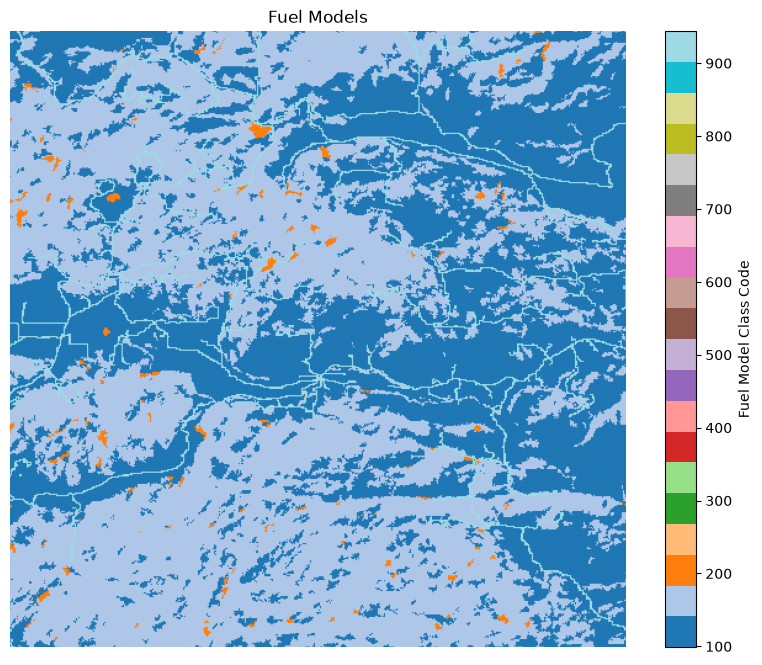

In [ ]:
# This overlaps with GeoTessera embedding render in tessera_download
# Upper left corner (I think):
# https://maps.app.goo.gl/tAK8nYtvXbRqJsJZA
# https://epsg.io/transform#s_srs=32613&t_srs=4326&x=457630.0000000&y=4527780.0000000
plt.figure(figsize=(10, 8))
plt.imshow(surface_fuels_data[:1000, :1000], cmap="tab20")
plt.title("Fuel Models")
plt.colorbar(label="Fuel Model Class Code")
plt.axis("off")
# plt.savefig("data/plot_output.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
# Show raw pixel values around the top left corner. Do they match up with the Forest Atlas view?
# Answer: Yeah, approximately...
with np.printoptions(threshold=np.inf):
    print(surface_fuels_data.squeeze()[:20, :20])

[[122 122 122 101 101 122 122 101 101 122 122 941 941 941 941 101 101 101
  101 122]
 [122 122 122 122 122 122 122 122 122 122 122 941 941 941 941 941 941 101
  101 122]
 [122 122 122 122 122 122 122 122 122 122 122 941 941 941 941 941 941 101
  101 122]
 [122 122 122 122 122 122 122 122 122 122 122 122 122 941 941 941 941 122
  122 122]
 [122 122 122 122 122 122 122 122 122 122 122 122 122 941 941 941 941 122
  122 122]
 [122 122 122 122 122 122 122 122 122 122 122 122 122 101 101 941 941 941
  941 122]
 [122 122 122 122 122 122 122 122 122 122 122 122 122 101 101 941 941 941
  941 122]
 [122 122 122 122 122 122 122 122 122 122 122 122 122 122 122 142 142 941
  941 122]
 [122 122 122 122 122 122 122 122 122 122 122 122 122 122 122 142 142 941
  941 122]
 [122 122 122 122 122 122 122 122 122 122 122 122 122 122 122 122 122 941
  941 941]
 [122 122 122 122 122 122 122 122 122 122 122 122 122 122 122 122 122 941
  941 941]
 [122 122 122 122 122 122 122 122 122 122 122 122 122 122 122 122

**Compare the above image to the same patch of embeddings in the `tessera_download` notebook.** Does it match?